# Is the world's electricity getting cleaner?
**SIADS 521, Assignment 3 · David Huang**

Over the last twenty years almost every country has added wind and solar. But a country's *share* of clean electricity can rise for two very different reasons: it builds clean power, or the rest of its power disappears. This dashboard lets you compare 160 countries from 2000 to 2023 and then drill into any one of them to see which of the two is happening.

**Live dashboard:** [https://siads521-energy.streamlit.app](https://siads521-energy.streamlit.app) (on the free tier it may need about a minute to wake up)  
**Video walkthrough (56 s):** [https://drive.google.com/file/d/1xX1RcMX277C-g4G_qBN3FzN4lbgF78j7/view?usp=sharing](https://drive.google.com/file/d/1xX1RcMX277C-g4G_qBN3FzN4lbgF78j7/view?usp=sharing)  
**Code and data:** [https://github.com/orbitsail/siads521-energy-dashboard](https://github.com/orbitsail/siads521-energy-dashboard)

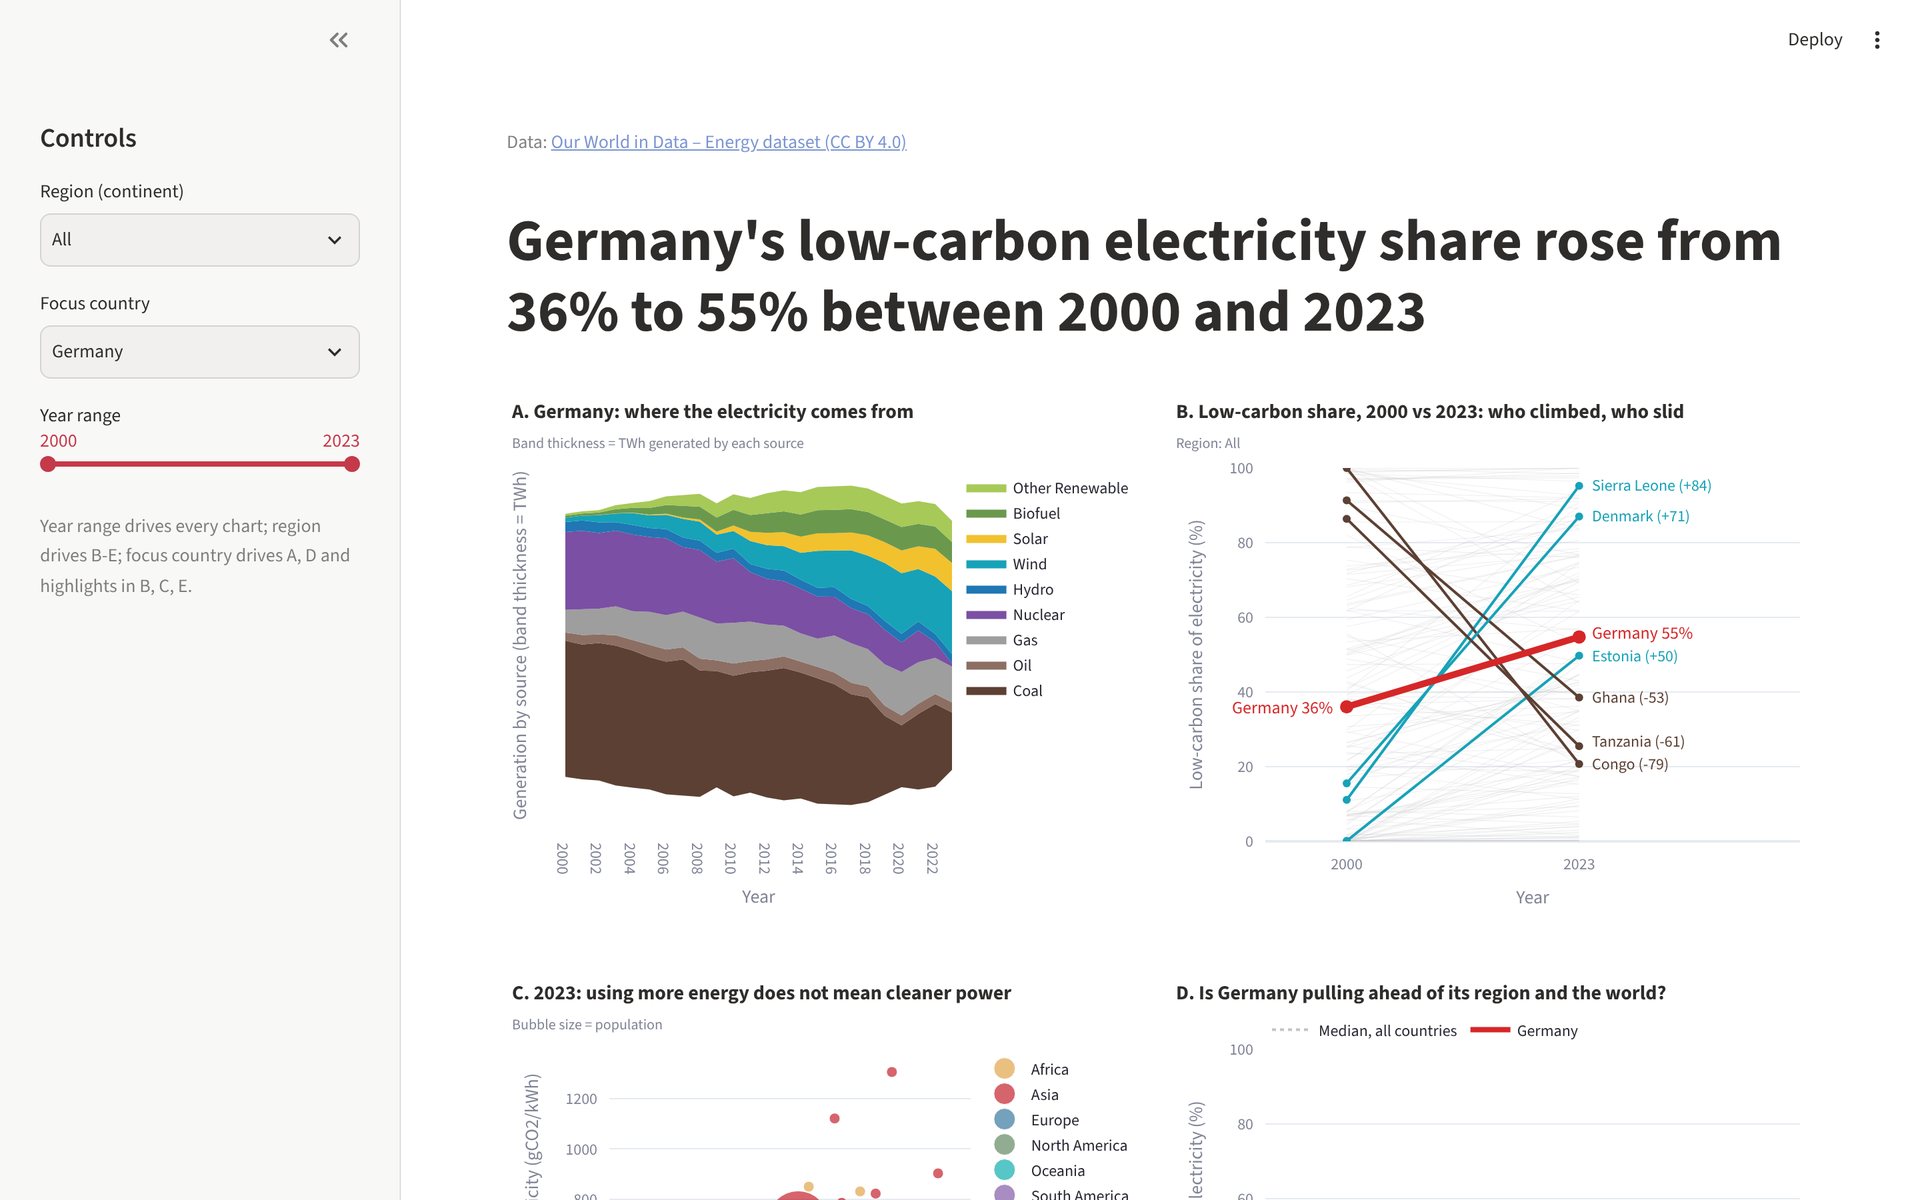

## Library choice and fit

I built the app with **Streamlit** and drew every chart with **Plotly**.

Streamlit was started in 2018 by Adrien Treuille, Thiago Teixeira and Amanda Kelly, and has been owned by Snowflake since 2022. It's open source under Apache 2.0. Plotly's Python library comes from Plotly Inc. and is MIT-licensed. Installing both is one line: `pip install streamlit plotly`.

The two sit on opposite sides of the declarative/procedural split, which is part of why they pair well. Streamlit is **procedural**: the app is a normal Python script that runs top to bottom, and every time someone touches a widget, the whole script runs again. Plotly is mostly **declarative**: I describe what a figure should contain (traces, axes, colors) and Plotly works out how to draw it.

Jupyter integration is uneven. Plotly figures show up inline in a notebook. A Streamlit app does not; it has to be launched with `streamlit run app.py` and opened in a browser. That's why this notebook shows code excerpts and screenshots instead of live widgets.

The limitations I actually ran into:
- **Every interaction reruns everything.** Fine for small data, slow for big data. I cache the data load with `@st.cache_data` so the CSV is read once.
- **It needs a running server.** Unlike Plotly, Bokeh or Panel, a Streamlit app can't be exported as a standalone HTML file, so hosting isn't optional.
- **Layout is basic.** You get columns, containers and a sidebar. Fine-grained placement, or clicking a point in one chart to filter another, needs extra work.

**Why it fits this data.** After cleaning, the dataset is 3,825 rows (160 countries × 24 years). At that size, rerunning the whole script costs milliseconds, so Streamlit's biggest weakness doesn't apply here. My questions also map directly onto three sidebar widgets: which region, which country, which years. And Plotly can draw both of my new chart types, a slope chart and a centered streamgraph, without adding another library.

**The alternative I rejected: Panel with hvPlot**, from the course tutorial. Its real advantage is exporting a self-contained HTML file. But linking several views inside a static file means writing JavaScript callbacks, and my data is small enough that a server costs me nothing. Free hosting on Streamlit Community Cloud settled it.

## Data

My data is Our World in Data's [energy dataset](https://github.com/owid/energy-data), released under **CC BY 4.0**. OWID compiles it mainly from the Energy Institute, Ember and the U.S. EIA; the codebook in the repo lists sources per column. It's one CSV: 23,195 rows and 130 columns, one row per country (or group of countries) per year, going back to 1900.

I only needed a fraction of it. The columns I keep:

| Columns | Unit | Used in |
|---|---|---|
| `<source>_electricity` for coal, oil, gas, nuclear, hydro, wind, solar, biofuel, other renewables | TWh | A |
| `low_carbon_share_elec` (nuclear + renewables) | % of electricity | B, D, E |
| `energy_per_capita` | kWh per person | C |
| `carbon_intensity_elec` | gCO2 per kWh | C |
| `population`, `country`, `iso_code`, `year`, plus a `continent` I add | | all |

The cleaning lives in `prep_data.py` in the repo. Here it is step by step. To rerun it, download the raw CSV from the OWID repo into this folder.

In [1]:
import pandas as pd
import country_converter as coco

df = pd.read_csv("owid-energy-data.csv")   # raw OWID file
df.shape

(23195, 130)

**Step 1: drop aggregates.** The file mixes real countries with groups such as "World", "Africa" and "High-income countries". Groups have no ISO code or one starting with `OWID_`, so they're easy to filter out. Leaving them in would put "Europe" in the same ranking as France.

In [2]:
df = df[df["iso_code"].notna() & ~df["iso_code"].astype(str).str.startswith("OWID")]
df["country"].nunique()

220

**Step 2: keep 2000–2023.** I checked how many countries have electricity data each year. In 2024 it's only about 100 of 220, because of reporting lags, so a 2024 comparison would mostly measure who has reported yet.

In [3]:
print(df.groupby("year")["electricity_generation"].count().loc[2021:2024])
df = df[df["year"].between(2000, 2023)].copy()

year
2021    213
2022    213
2023    174
2024    100
Name: electricity_generation, dtype: int64


**Step 3: add a continent.** The dataset has no region column, and region is one of my main filters. I map ISO codes with `country_converter`, which lumps the Americas together, so I split them into North and South America by hand. Anything that can't be mapped is dropped. That turns out to be only Netherlands Antilles, which was dissolved in 2010.

In [4]:
cc = coco.CountryConverter()
iso = df["iso_code"].drop_duplicates()
df["continent"] = df["iso_code"].map(dict(zip(iso, cc.convert(iso.tolist(), src="ISO3", to="continent"))))
SOUTH = {"ARG","BOL","BRA","CHL","COL","ECU","GUY","PRY","PER","SUR","URY","VEN","FLK","GUF"}
df.loc[df["continent"] == "America", "continent"] = df["iso_code"].apply(
    lambda c: "South America" if c in SOUTH else "North America")
bad = df["continent"].isna() | (df["continent"] == "not found")
print("Dropped:", sorted(df.loc[bad, "country"].unique()))
df = df[~bad]

ANT not found in ISO3


Dropped: ['Netherlands Antilles']


**Step 4: keep countries with at least 1 million people (2023).** In a micro-state a single new plant can move the share by 40 points. Left in, they'd crowd the top of every ranking without saying much about how energy systems change. 160 countries remain.

In [5]:
pop23 = df[df["year"] == 2023].set_index("country")["population"]
df = df[df["country"].isin(pop23[pop23 >= 1_000_000].index)]
df["country"].nunique()

160

**Step 5: fix one inconsistent column name.** OWID calls generation `other_renewable_electricity` but the share `other_renewables_share_elec`. I rename the share so all nine sources follow the same pattern, which keeps the chart code to one loop.

In [6]:
df = df.rename(columns={"other_renewables_share_elec": "other_renewable_share_elec"})
SOURCES = ["coal","gas","oil","nuclear","hydro","wind","solar","biofuel","other_renewable"]
cols = (["country","iso_code","continent","year","population","energy_per_capita",
         "carbon_intensity_elec","electricity_generation"]
        + [f"{s}_electricity" for s in SOURCES] + [f"{s}_share_elec" for s in SOURCES]
        + ["low_carbon_share_elec","fossil_share_elec"])
clean = df[cols].sort_values(["country","year"]).reset_index(drop=True)
clean.shape

(3825, 28)

**Missing values.** After cleaning, no column is more than 1.2% missing; the worst is gas, at 47 of 3,825 rows. I chose **not to impute**. Filling a gap means guessing a country's energy mix, and my charts are about change, so a guess would quietly invent a trend. Instead each chart skips a country when the value it needs is missing. The 3,825 rows are 158 countries with all 24 years, plus South Sudan (independent in 2011) and Timor-Leste, whose records are shorter.

In [7]:
miss = clean.isna().sum()
print((miss[miss > 0] / len(clean) * 100).round(1).sort_values(ascending=False).head(5).to_string())
print("Matches the app's data file:", clean.shape == pd.read_csv("../data/energy_clean.csv").shape)

gas_electricity                1.2
gas_share_elec                 1.2
wind_electricity               1.0
wind_share_elec                1.0
other_renewable_electricity    0.8
Matches the app's data file: True


## Visualization techniques

Every screenshot in this section uses the same settings: Asia, focus country India, 2010–2023. One color always means the same energy source in every chart, and red is always the focus country.

### A. Streamgraph (new to this course): one country's electricity mix

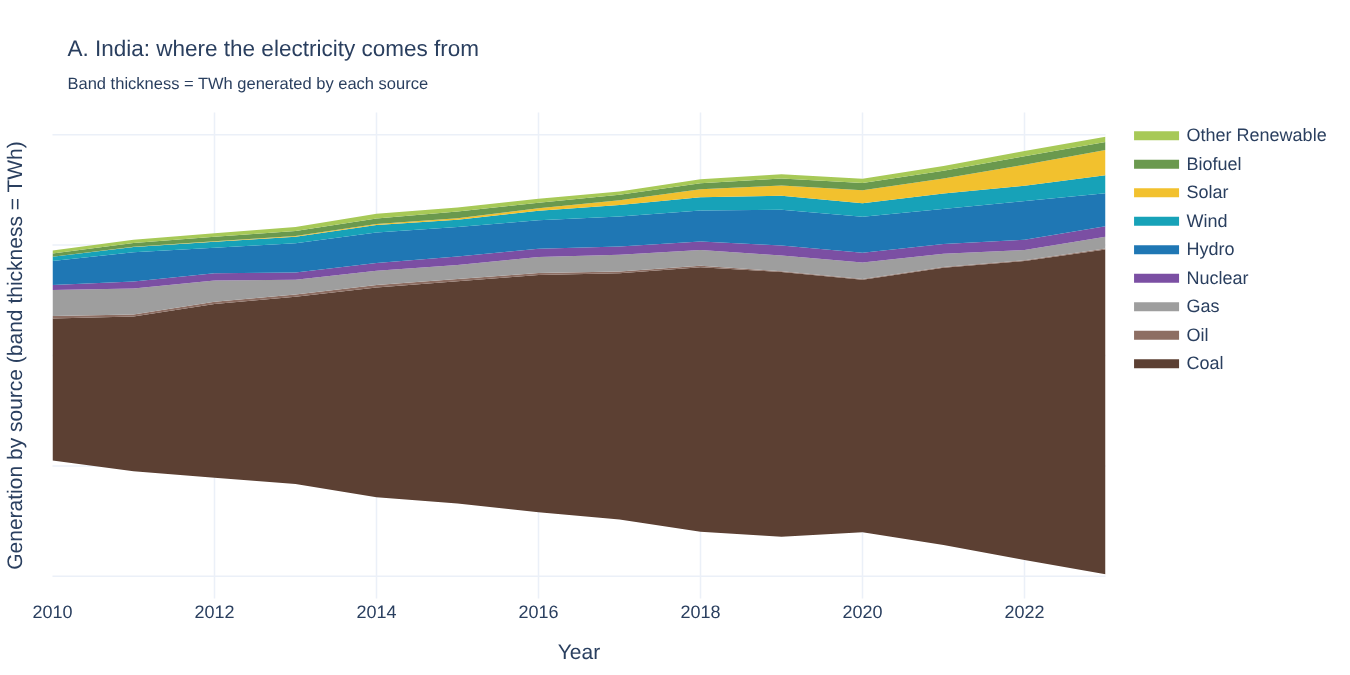

**What it shows.** Each colored band is one source, and its thickness is the terawatt-hours it generated that year. The shape is centered on zero, so vertical position means nothing; only thickness does. Hovering shows the exact TWh.

**Why here.** The question needs two things at once: is the country making more or less electricity, and what is it made from? Covered charts each give up one of them. A line chart with nine sources would be a tangle. A stacked bar chart breaks time into separate years and makes it hard to see when a shift started. A 100% stacked chart hides the total, and in this data the total turned out to matter more than anything else (see Lebanon, below). The streamgraph is the only one of these that keeps both the total and the mix visible. In India's case you can see in one glance that the stream roughly doubled, and that coal, not solar, carried most of that growth.

**When not to use it.** When readers need precise values: the bands curve, so nothing can be read off an axis. And when many categories are tiny: they turn into hairlines nobody can see.

### B. Slope chart (new to this course): who got cleaner, who didn't

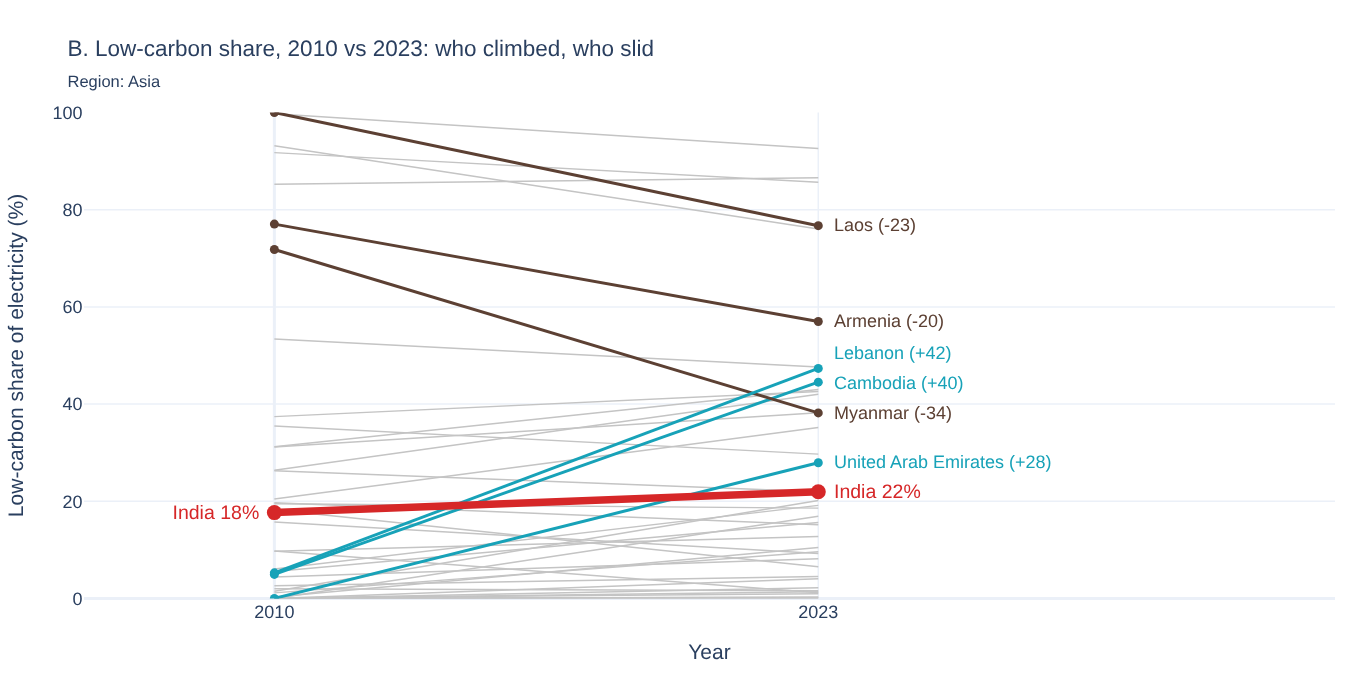

**What it shows.** Each country in the selected region is one line from its low-carbon share in the start year to its share in the end year. Up means cleaner. Grey is context, the three biggest risers are blue, the three biggest fallers are brown, and the focus country is red.

**Why here.** I care about direction and size of change for dozens of countries at once. A grouped bar chart with two bars per country makes your eyes jump between pairs. A line chart of all 24 years for 47 countries would be unreadable. The slope chart throws away the middle years on purpose and leaves only what I'm asking about, so a steep line pops out immediately. That's how Lebanon first caught my attention.

**When not to use it.** When the path matters, not just the endpoints. A country that crashed and recovered looks flat here. That's exactly why it's paired with charts A and D.

### C. Scatter plot: energy use vs. carbon intensity

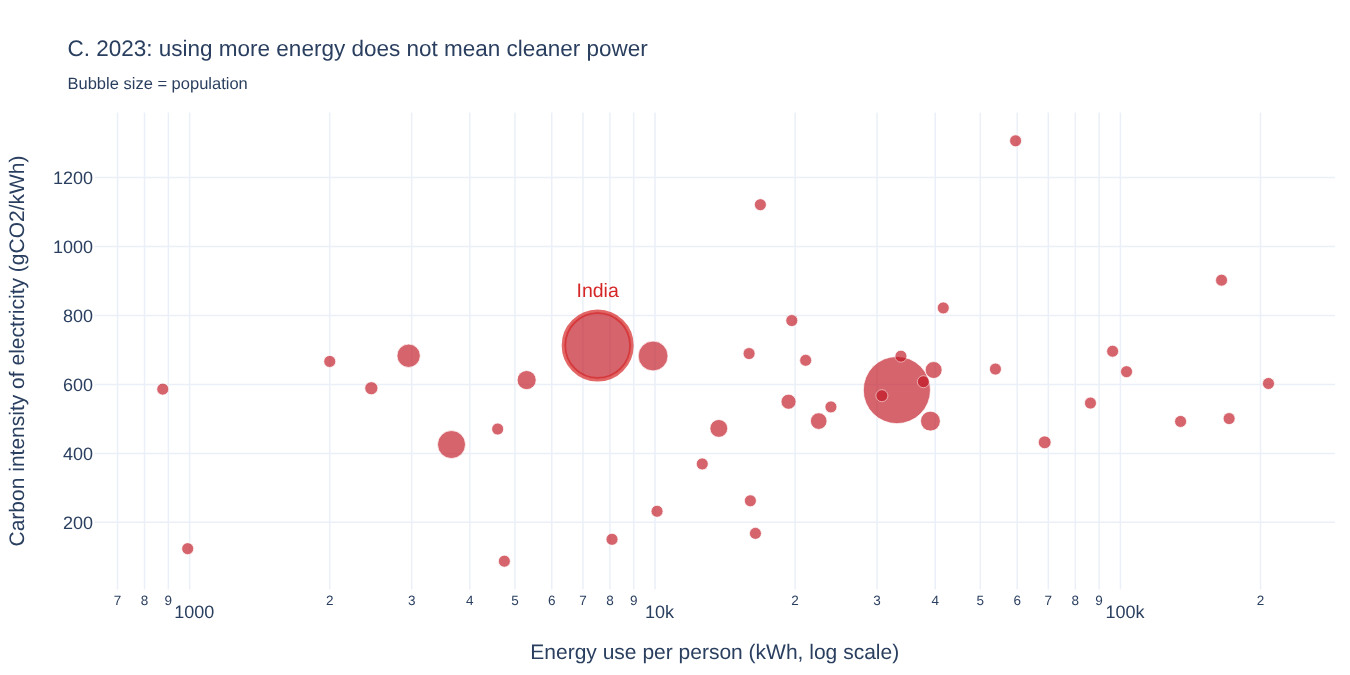

**What it shows.** Each bubble is a country in the end year: energy use per person on x, grams of CO2 per kWh of electricity on y, bubble area by population.

**Why here.** It tests an assumption I came in with, that countries using more energy are richer and therefore have cleaner grids. The bubbles don't line up, in any region I tried. The x-axis is logarithmic because energy use per person runs from a few hundred kWh to over 200,000; on a linear axis most countries would be squashed against the left edge by a handful of oil exporters.

**When not to use it.** When points overlap into a blob, or when the question is about change over time, since it only shows one year.

### D. Line chart: the focus country against its region and the world

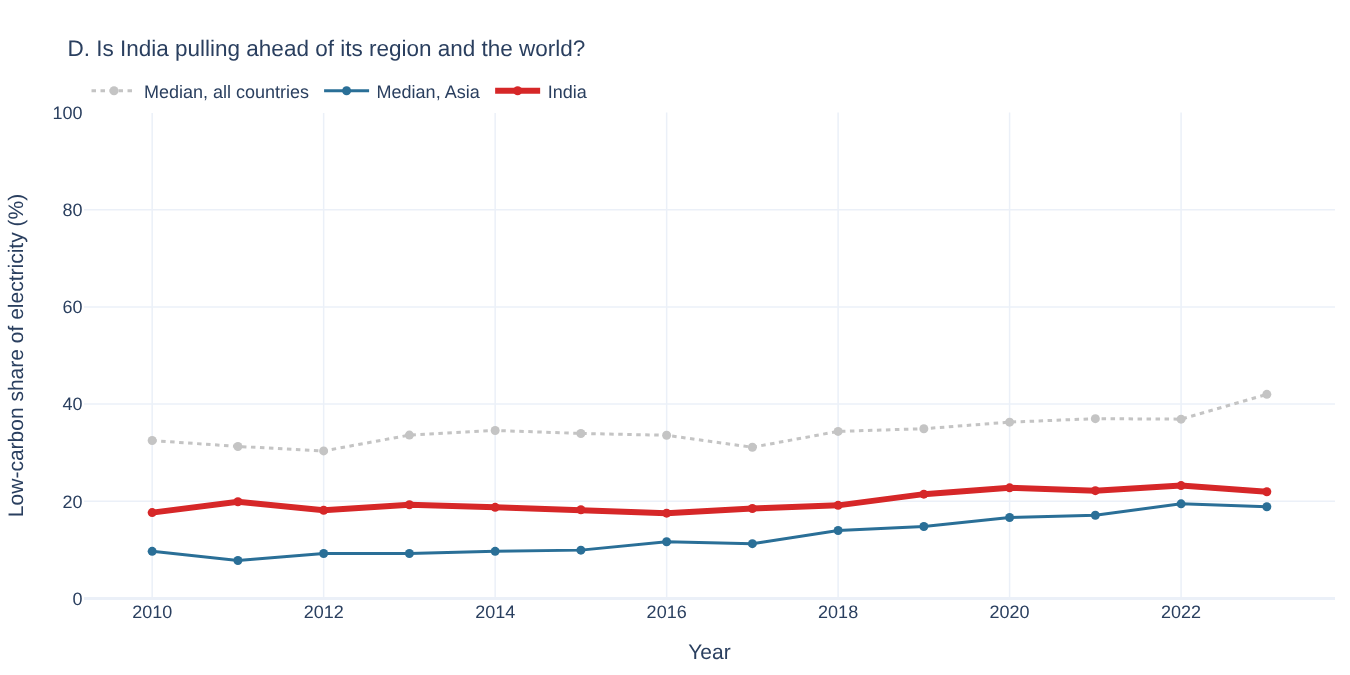

**What it shows.** The red line is the focus country's low-carbon share each year, the blue line is the median of its region, and the dotted grey line is the median of all 160 countries. The y-axis is fixed at 0–100% so switching countries can't quietly rescale it.

**Why here.** "India: 22%" means little without "compared to what?". India sits above the Asian median but well below the world median, and the gap isn't closing. I use medians, not means, because the shares are skewed: a few hydro-heavy countries sit near 100% and would drag a mean upward.

**When not to use it.** Past four or five lines a line chart becomes spaghetti, which is why it shows one country against two reference lines instead of every country.

### E. Bar chart: the biggest gains, ranked

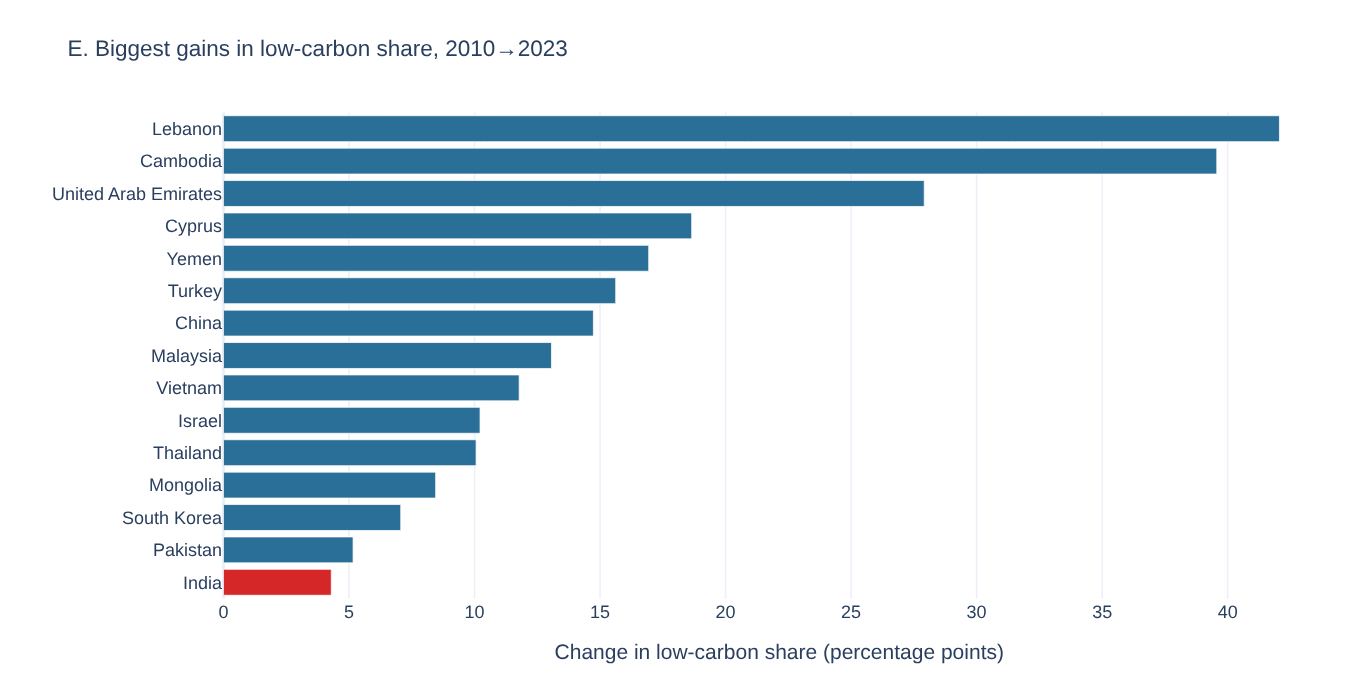

**What it shows.** The 15 countries in the region whose low-carbon share rose most, in percentage points, sorted longest first. The axis starts at zero so bar length is honest.

**Why here.** The slope chart is good for direction but bad for ranking: by eye you can't tell +40 from +42. This puts an exact order on the same numbers.

**When not to use it.** On its own. It only shows the top of the list, so it suggests everyone is improving. Next to the slope chart, the fallers are still in view.

### How the charts work together

The layout follows the order I explored in. B and E look across the whole region and point at countries worth a closer look. A and D then zoom into one country. C sits alongside as a check on a different dimension.

The pairing that matters most is **share versus size**. B, D and E are all percentages; A is the only chart in absolute terms. Read alone, the percentage charts can tell a story the absolute numbers flatly contradict, and putting them side by side under the same controls is the point of the dashboard.

## Building the dashboard

The full app is `app.py` in the repo (about 230 lines). I built it in three stages.

**Stage 1: one chart, hard-coded.** I started with the streamgraph for one country, because it was the chart I was least sure Plotly could do. Plotly has no streamgraph type, but a stacked area chart with a shifted baseline is one. I add an invisible trace at minus half the yearly total, then stack each source on top with `fill="tonexty"`. Because the y-values are shifted, the hover text has to show the real TWh, which I pass through `customdata`:

```python
vals  = d[[f"{s}_electricity" for s in SOURCES]].fillna(0).to_numpy()
total = vals.sum(axis=1)
cum   = -total / 2                                   # centered baseline
fig.add_trace(go.Scatter(x=years, y=cum, line=dict(width=0), hoverinfo="skip", showlegend=False))
for i, s in enumerate(SOURCES):
    cum = cum + vals[:, i]
    fig.add_trace(go.Scatter(x=years, y=cum, fill="tonexty", line=dict(width=0),
                             fillcolor=SRC_COLORS[s], name=SRC_LABELS[s], customdata=vals[:, i],
                             hovertemplate=f"{SRC_LABELS[s]}: %{{customdata:.1f}} TWh"))
```

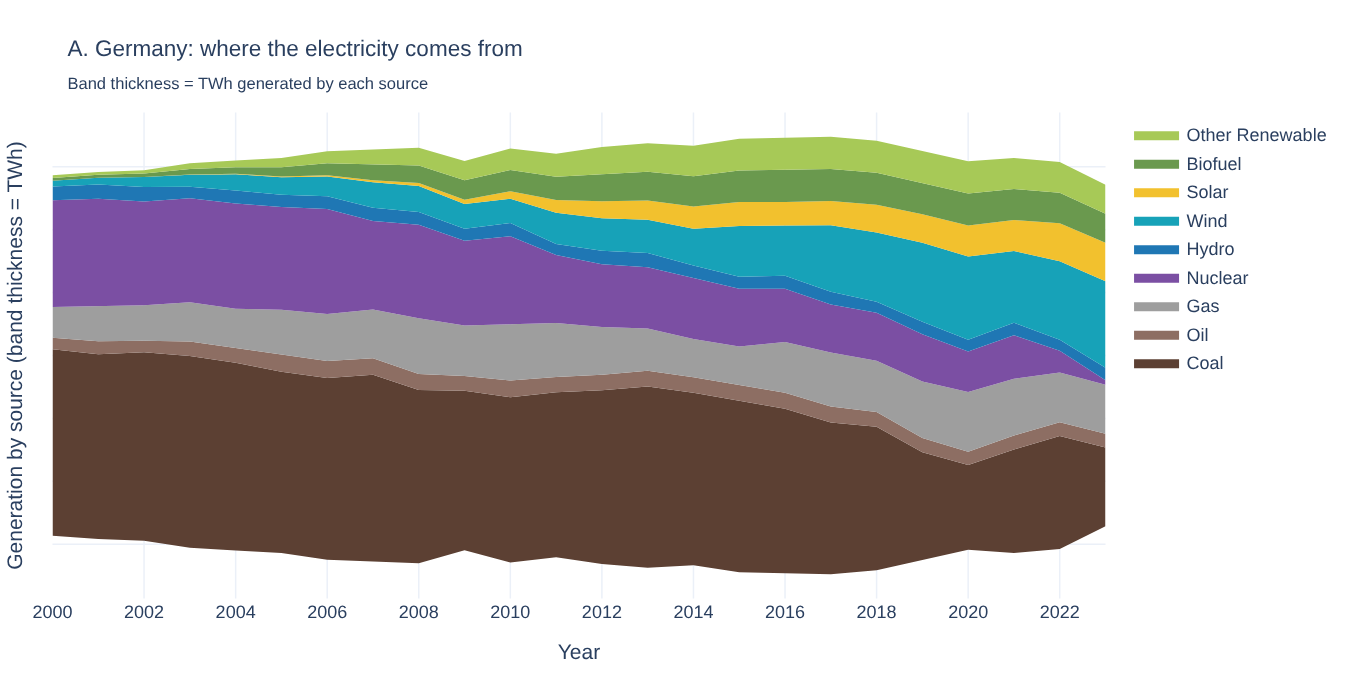

**Stage 2: all five charts and a layout.** Each chart became a function that returns a Plotly figure, sharing one color dictionary and one base layout. They go into two columns so everything fits on one scrolling page, with no tabs:

```python
c1, c2 = st.columns(2)
with c1:
    show(streamgraph(), "A", nodata)
    show(scatter(), "C", "No scatter data for this selection.")
    show(bars(), "E", "No countries with data at both start and end year.")
with c2:
    show(slope(), "B", "No countries with data at both start and end year.")
    show(lines(), "D", nodata)
```

`show()` puts a short message on the page instead of an empty chart when a selection has no data, such as a year range in which a country has no records.

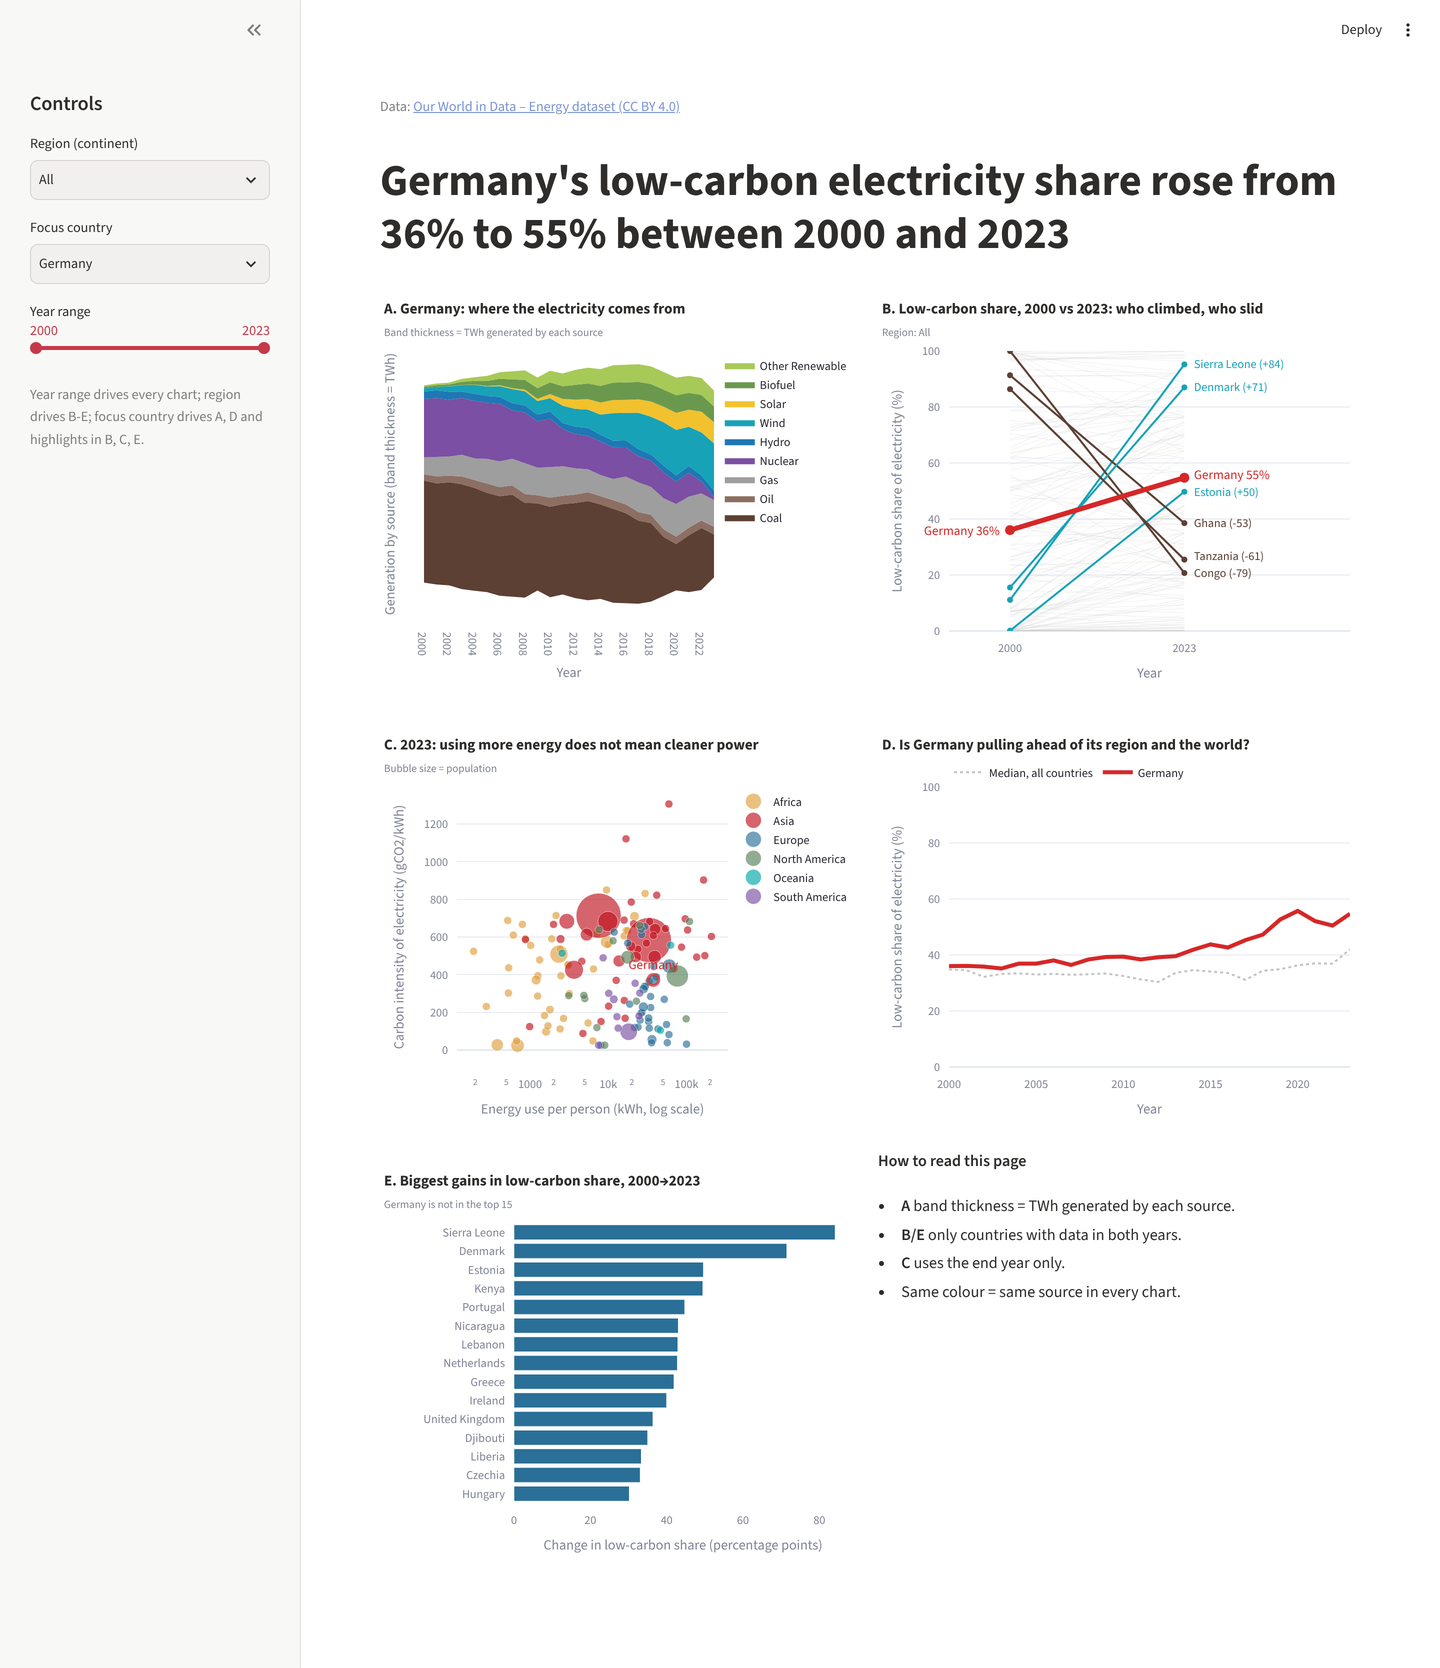

**Stage 3: linking.** Three sidebar widgets drive everything (simplified excerpt): Because Streamlit reruns the whole script on every change, linking is mostly a matter of every chart function reading the same variables:

```python
region = st.sidebar.selectbox("Region (continent)", ["All"] + sorted(df["continent"].unique()))
rdf    = df if region == "All" else df[df["continent"] == region]      # feeds B, C, D, E
focus  = st.sidebar.selectbox("Focus country", sorted(rdf["country"].unique()))   # feeds A, D; red in B, C, E
y0, y1 = st.sidebar.slider("Year range", 2000, 2023, (2000, 2023))      # feeds all five
```

The year slider updates all five charts at once; the region updates four; the focus country redraws two and moves the red highlight in the other three. The page headline is generated from the same values, so it always states the current result, e.g. *"Lebanon's low-carbon electricity share rose from 5% to 47% between 2010 and 2023"*.

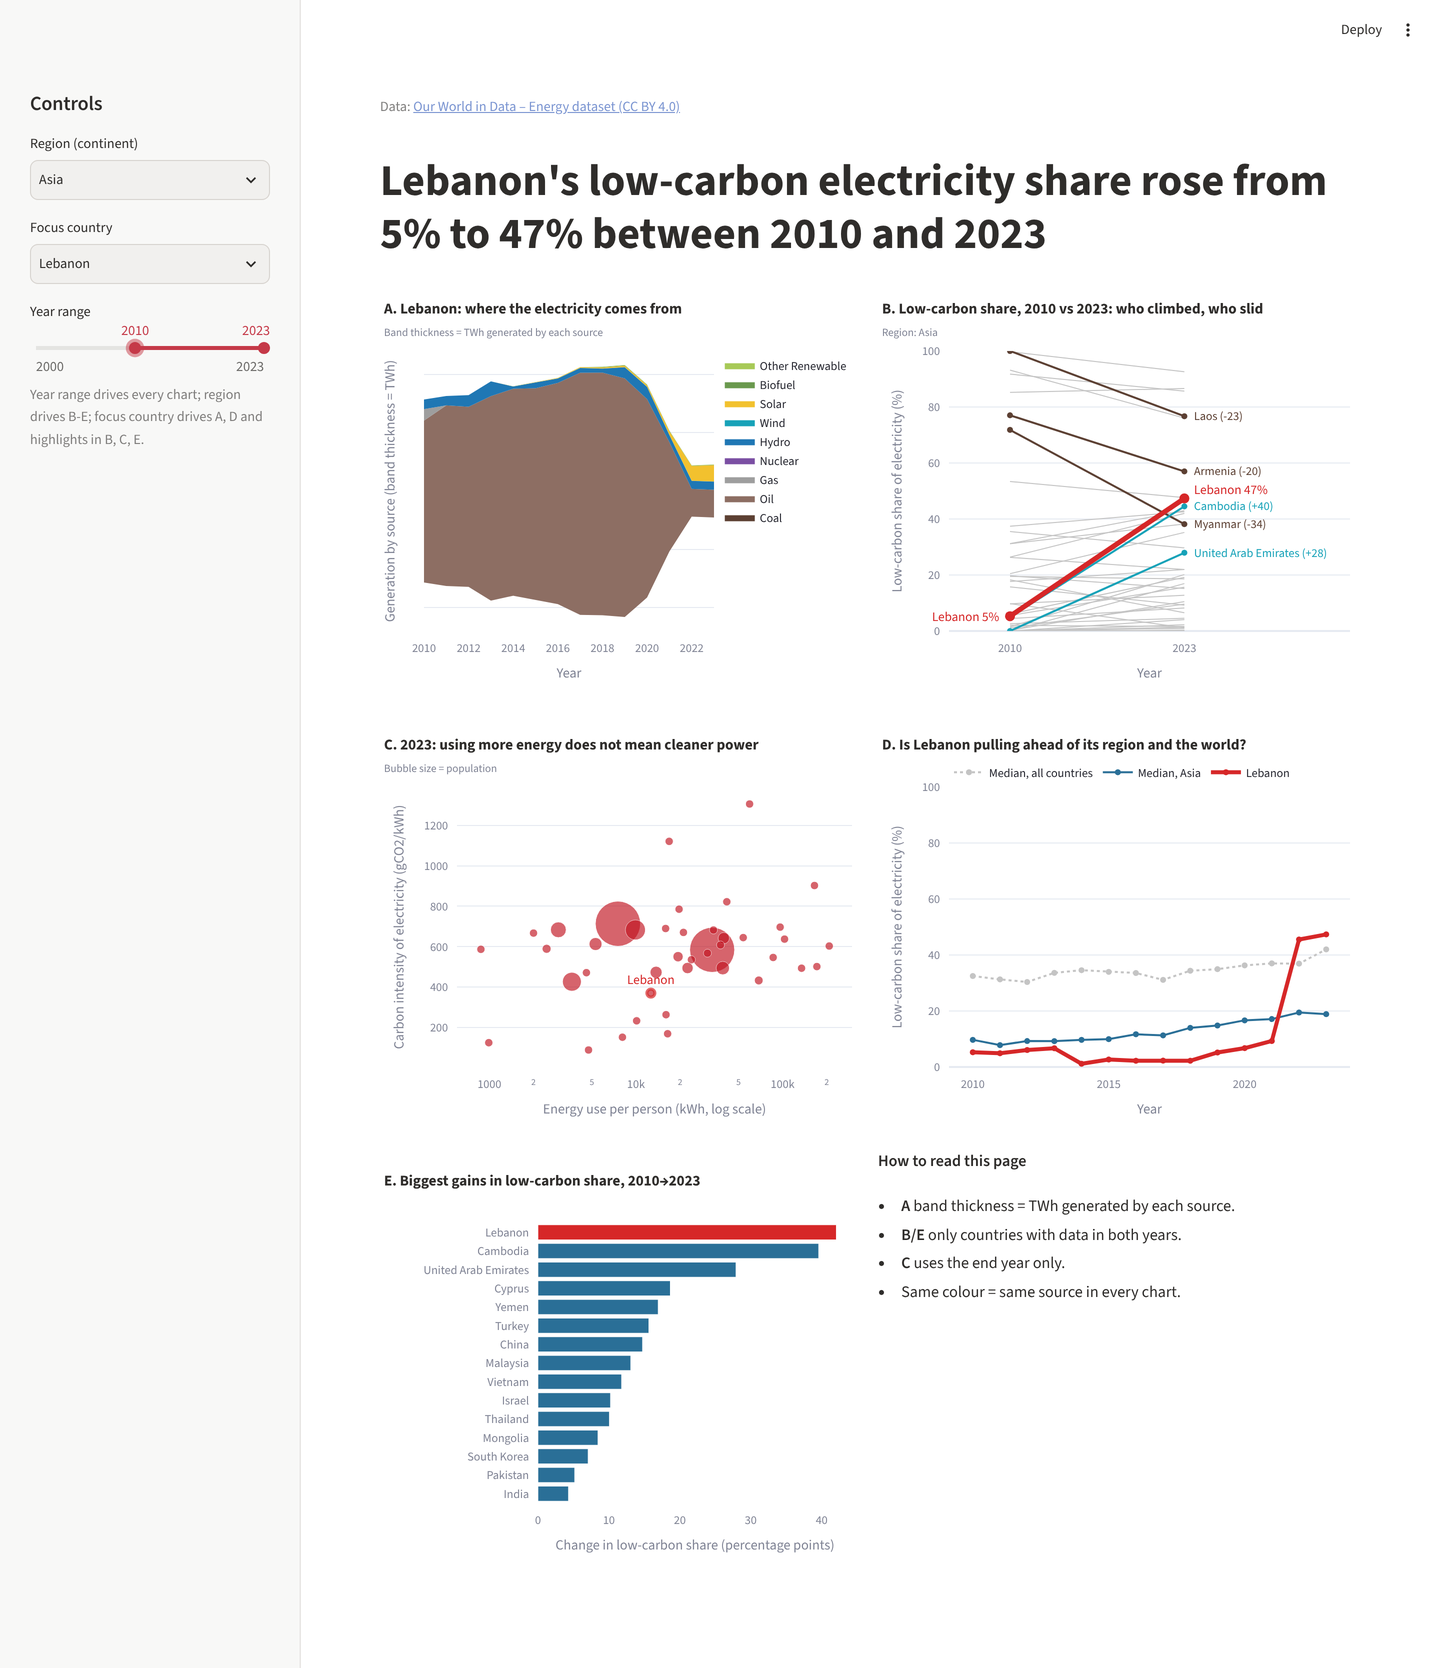

## Exploring: what I asked, where I got stuck, what I found

I came in with two questions. Which countries cleaned up their electricity fastest? And do countries that use more energy have cleaner grids?

The second question went nowhere. In the scatter plot, energy use and carbon intensity simply don't line up, in any region or year I tried. I kept the chart, because "no relationship" is worth knowing, but it stopped being my main thread.

The first question needed two corrections. My first version of the slope chart drew all 160 countries at the same weight, and the result was a grey hairball; I made the background lines thinner and fainter and mostly explored one continent at a time. Then I misread the fallers. I assumed a falling line meant a country going backwards. Laos looked like the worst case, from 100% low-carbon in 2010 to 77% in 2023. But its streamgraph shows hydro output growing almost fivefold, from 8 to 40 TWh. The share fell only because Laos also added 12 TWh of coal. Falling share, growing clean power. After that I stopped trusting a share without checking the total.

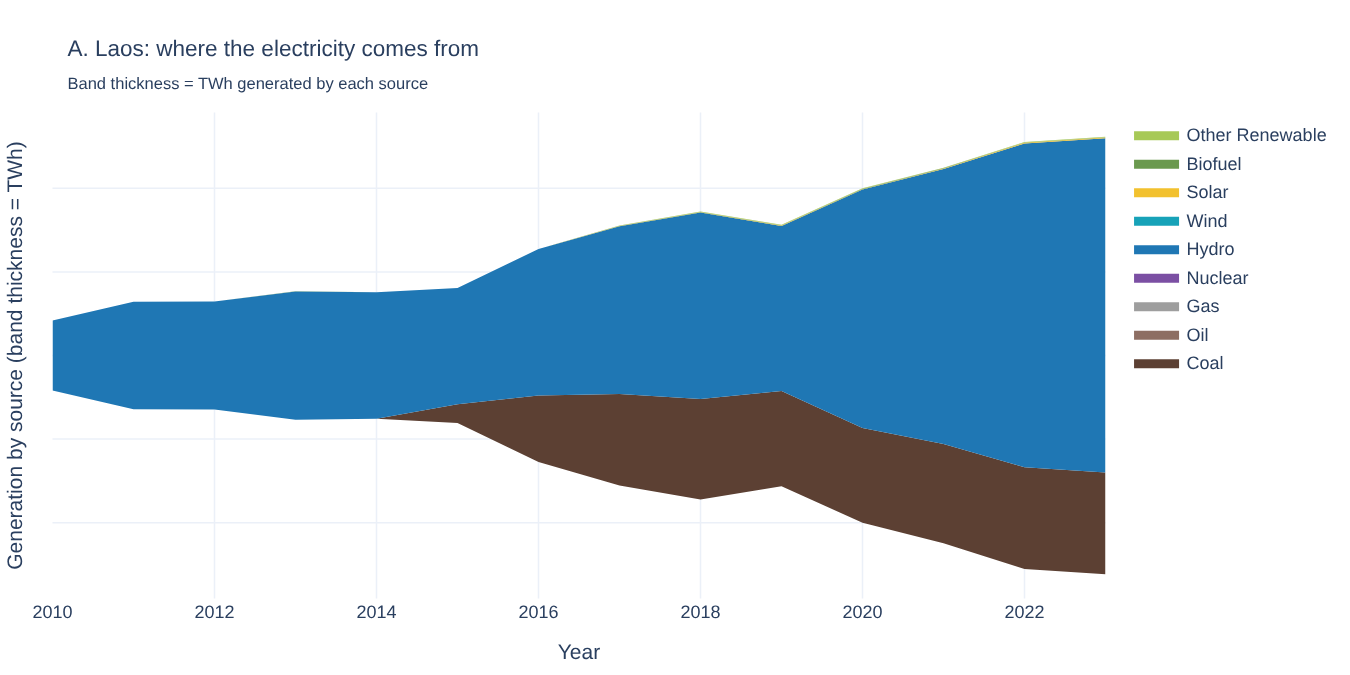

### Finding 1: Lebanon's "green transition" is a blackout

With Asia selected and the years set to 2010–2023, Lebanon tops both the slope chart and the ranking. Its low-carbon share jumped from 5% to 47%, more than any other country in the region.

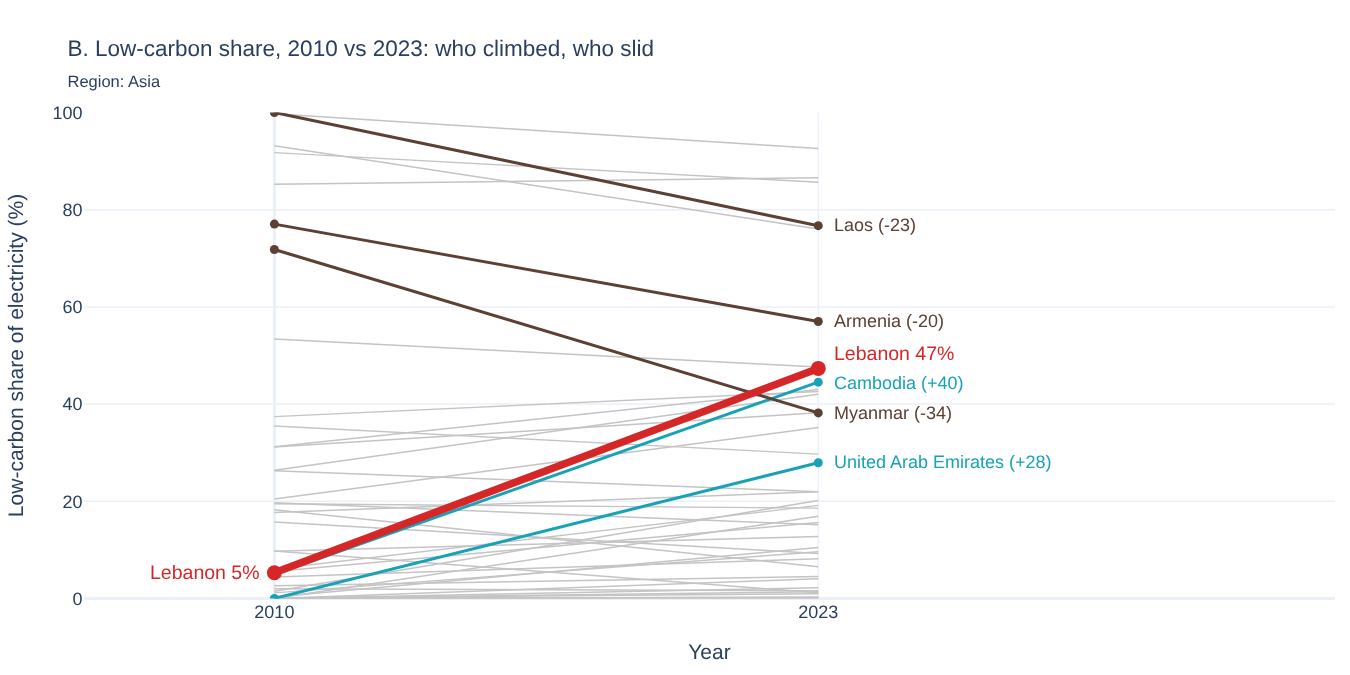

Honestly, my first thought was "why Lebanon?" It's not a country I'd ever heard mentioned in a clean-energy story. The longer I looked, the stranger it got. Energy systems don't change that fast. A country can build a lot of solar in a decade, but its share doesn't jump forty points in two years. So I looked it up, and the answer was an energy crisis: from 2019 on, Lebanon could barely pay for fuel, and the grid went dark for most of the day. That's when it clicked. When the total collapses, the percentage stops telling you anything. Lebanon's share went up, but its 47% was close to a misleading number.

Switching the focus country to Lebanon shows it directly. The whole stream collapses after 2019: total generation falls from 21.6 TWh to 4.4 TWh in 2022, about 80%, almost all of it oil-fired power (20.5 → 2.4 TWh). Solar did grow, but only to 1.4 TWh.

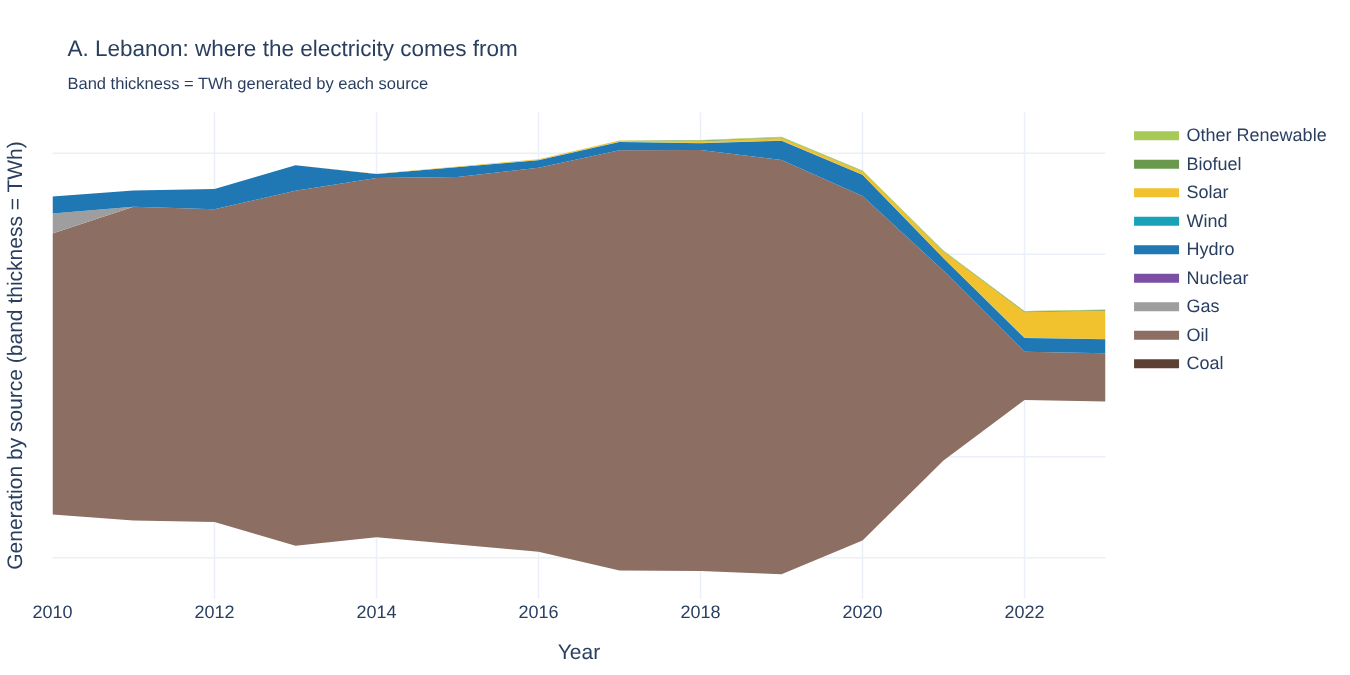

**Why this needed interaction.** No single chart here tells both halves. The three percentage charts all say "success"; only the absolute view says "crisis". I found it by noticing Lebanon in a regional view and then making it the focus country. A static report would have had to choose in advance which country got a streamgraph, and Lebanon is not a country anyone would pick. One caveat: much of Lebanon's power now comes from private diesel generators, which very likely aren't in national statistics, so even the remaining fossil share is probably understated.

### Finding 2: Germany's climb wasn't a straight line

Over 2000–2023 the slope chart shows Germany climbing smoothly from 36% to 55%. The streamgraph shows what's underneath: nuclear shrank from 170 TWh to 7 TWh while wind and solar grew from 9 TWh to nearly 200. Germany swapped one kind of low-carbon power for another.

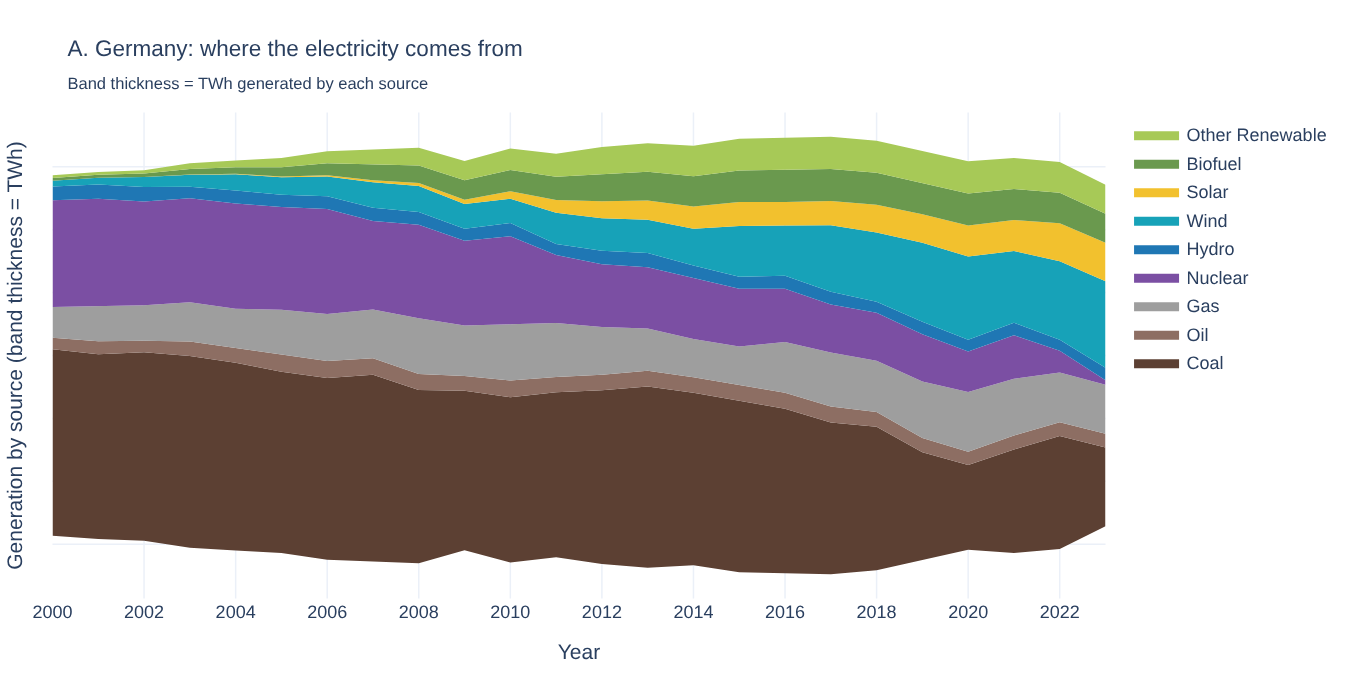

Moving the end of the year slider shows a step back that the endpoints hide. The share fell from 55.7% in 2020 to 50.5% in 2022, as coal generation rose again from 135 to 180 TWh during the energy crisis that followed the war in Ukraine. Even the 2023 recovery is partly a denominator effect, since total generation dropped about 12% that year. This one is less dramatic than Lebanon, and the dip is visible in chart D on its own, but it's the same lesson at a smaller scale.

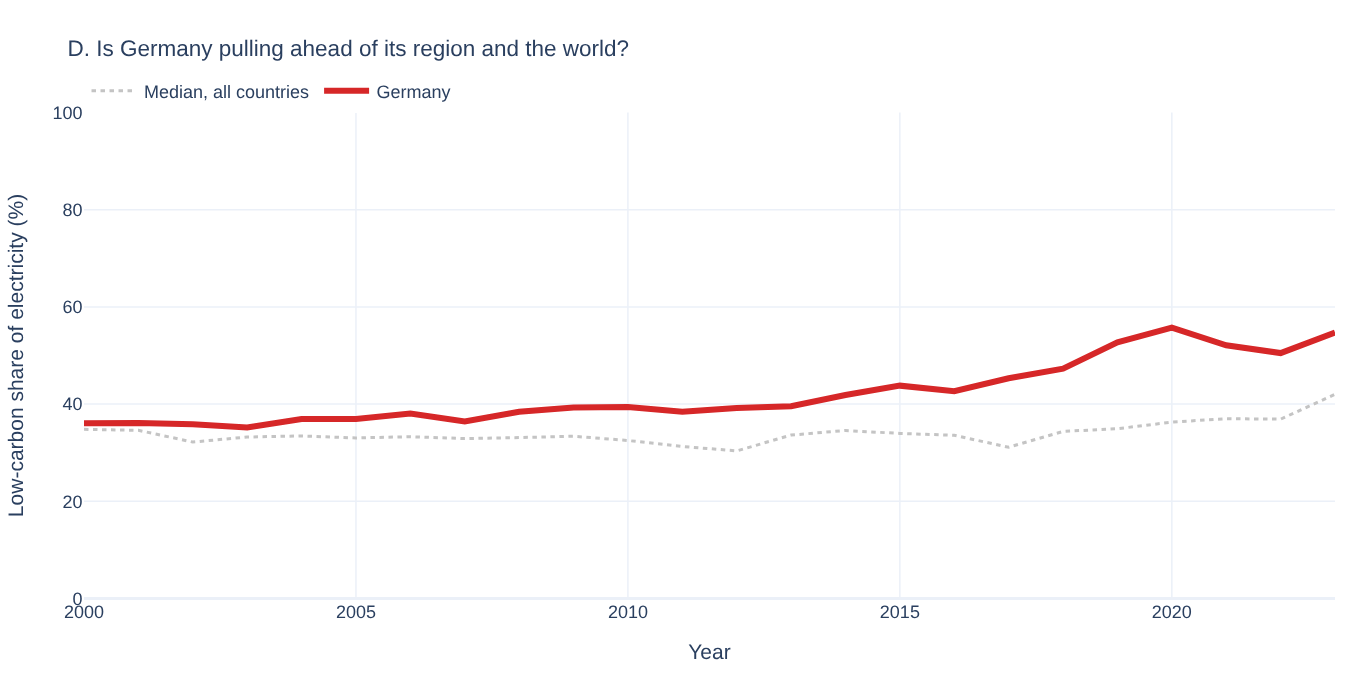

**What interaction added overall.** Both findings came from the same move: spotting a country in a regional view, then making it the focus. The dashboard's job is to make that move one click.

## AI log and troubleshooting

I used **Claude (Anthropic)** throughout: to compare candidate datasets, to write and debug `prep_data.py` and `app.py`, to walk through deployment, and to draft the English text of this notebook, which I reviewed and edited. The dataset and library choices, the exploration and the findings were mine to check and sign off on. These are the places where it went wrong.

**Entry 1: A dataset I wasn't allowed to share**
- Tool: Claude
- What I asked for: a clean, rich dataset on housing prices.
- What came back: a strong recommendation for Redfin's Data Center, for good reasons: tidy monthly files, many metrics, split by property type.
- What was wrong: the license. Redfin's terms limit the data to personal, non-commercial use and restrict redistribution. This assignment needs public or shareable data, and my dashboard publishes the data on the open web.
- How I noticed: before committing, I had the recommendation checked against Redfin's actual terms of use.
- What I did instead: switched to Our World in Data's energy dataset (CC BY 4.0). Lesson: "free to download" is not "free to share".

**Entry 2: The plan assumed data that wasn't there**
- Tool: Claude
- What I asked for: a plan for the dashboard on the OWID data.
- What came back: a plan that used data up to the latest year (2024) and put GDP per capita on the scatter plot.
- What was wrong: only about 100 of 220 countries have electricity data for 2024, and GDP is empty for every country from 2023 on.
- How I noticed: counting non-missing values per year before building anything (the check is in the Data section).
- What I did instead: limited the dashboard to 2000–2023 and replaced GDP with energy use per person, which is nearly complete.

**Entry 3: A cleaning step that silently did nothing**
- Tool: Claude
- What I asked for: a step that adds a continent to each country and drops any that can't be mapped.
- What came back: code calling `country_converter` with `not_found=None`.
- What was wrong: with that argument, unknown codes come back as themselves, not as a blank. Netherlands Antilles got the "continent" `ANT`, passed the filter, and the list of dropped countries printed empty.
- How I noticed: the library printed a warning that `ANT` wasn't found, while the script said nothing had been dropped. The two outputs contradicted each other.
- What I did instead: removed `not_found=None`, so unmapped codes return "not found" and are filtered out. (The population filter would have removed this territory later anyway, but the step wasn't doing what it claimed.)

**Entry 4: The draft invented things I never did**
- Tool: Claude
- What I asked for: draft text explaining why I chose each chart.
- What came back: fluent paragraphs saying I had "tried" a nine-line chart that "turned into spaghetti", and a grouped bar chart I "gave up on after ten countries".
- What was wrong: neither happened. The reasoning was fine, but it was presented as my experience.
- How I noticed: I asked whether the dead ends in the draft had actually happened, and Claude admitted those two were made up.
- What I did instead: rewrote them as reasoning ("a line chart with nine sources would be a tangle") and kept only dead ends that really came up while building. Since I'm responsible for every claim in this notebook, this was the one that mattered most to me.

**Entry 5: Deployment form details** (troubleshooting, not an AI error)
- Tool: none (Streamlit Community Cloud's deploy form)
- What I was trying to do: deploy `app.py` from my GitHub repo.
- What happened: the "Main file path" field autocompletes while you type, and the text got mixed into a wrong value (`prep_data.pysiads521-energy`). Separately, the form defaulted to Python 3.14, while the app was tested on 3.13.
- How I noticed: reading the form back before clicking Deploy.
- What I did instead: picked `app.py` from the dropdown instead of typing it, and set Python to 3.13 under Advanced settings so the cloud matched my tested environment.

## Deployment

The dashboard runs on **Streamlit Community Cloud**, which is free for apps in public GitHub repos.

1. **Put the app in a public GitHub repo.** It needs `app.py`, the cleaned data (`data/energy_clean.csv`, about 600 KB), and a `requirements.txt` with pinned versions: `streamlit==1.67.0`, `plotly==7.1.0`, `pandas==3.0.5`. The app reads the data with a relative path, which works because Streamlit Cloud runs from the repo root.
2. Go to [share.streamlit.io](https://share.streamlit.io) and **sign in with GitHub**. The first time, it asks permission to read your repos.
3. Click **Create app → Deploy a public app from GitHub**.
4. Fill in **Repository** (`orbitsail/siads521-energy-dashboard`), **Branch** (`main`) and **Main file path** (`app.py`). Pick the file from the dropdown rather than typing it.
5. Optional: choose a readable **App URL** (I used `siads521-energy`).
6. Open **Advanced settings** and set the **Python version** to the one you tested locally (3.13 for me).
7. Click **Deploy**. The first build installs the requirements and takes 2–3 minutes. After that, every push to `main` redeploys automatically.
8. **Test it in a private browser window**, where you're not signed in to anything, and try every control.

On the free tier an app sleeps after a period without visitors; the next visitor sees a "wake up" button and waits about a minute.

Live app: [https://siads521-energy.streamlit.app](https://siads521-energy.streamlit.app)